# 01 - Exploratory Data Analysis: IoT Sensor Data

Goal: understand the virtual factory's sensor data **before** building any model.

Questions we answer:
1. What do the sensor readings look like?
2. How rare are failures?
3. Which sensors behave differently right before a failure?

In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))   # let the notebook import from src/

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
from src.data_loader import load_dataset

sns.set_theme(style='whitegrid')
df, source = load_dataset()
df.head()

[LOAD] Source : Virtual IoT simulator (cached)
[LOAD] Shape  : 10,000 rows x 14 columns


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M39403,M,300.8,309.1,1651,33.8,3,0,0,0,0,0,0
1,2,L96979,L,300.8,309.1,1627,35.2,5,0,0,0,0,0,0
2,3,H60860,H,300.8,309.2,1783,26.3,10,0,0,0,0,0,0
3,4,M94022,M,300.8,309.2,1571,39.6,13,0,0,0,0,0,0
4,5,L44223,L,300.8,309.2,1576,37.3,15,0,0,0,0,0,0


## 1. Dataset overview

In [2]:
df.info()
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.00,1539.11,40.23,111.69,0.04,0.00,0.00,0.02,0.01,0.00
std,2886.90,2.0,2.75,162.87,10.47,64.47,0.19,0.07,0.04,0.14,0.11,0.03
min,1.00,297.0,306.10,1168.00,3.80,2.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.7,308.00,1427.00,33.30,56.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,299.2,309.10,1540.00,40.00,111.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.4,312.90,1649.00,47.00,167.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,305.5,316.60,2218.00,91.40,254.00,1.00,1.00,1.00,1.00,1.00,1.00


## 2. How rare are failures?
Only ~3-4% of machine cycles end in failure. This **class imbalance** is why accuracy alone is a misleading metric.

Machine failure
0    9615
1     385
Name: count, dtype: int64
Failure rate: 3.85%


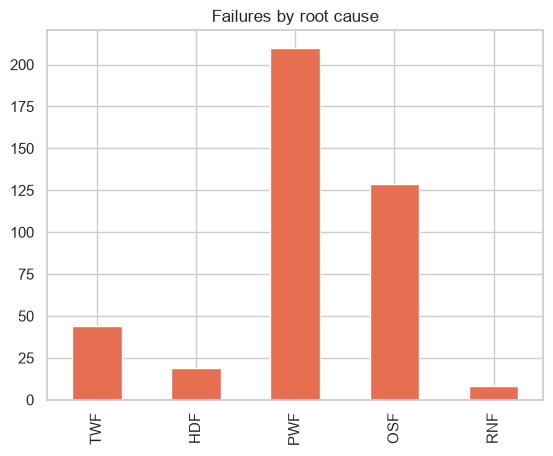

In [3]:
print(df[config.TARGET].value_counts())
print(f"Failure rate: {df[config.TARGET].mean():.2%}")
df[config.FAILURE_MODES].sum().plot.bar(title='Failures by root cause', color='#e76f51');

## 3. Sensor behaviour: healthy vs failing machines

C:\Users\Nischay\AppData\Local\Temp\ipykernel_12372\4175360339.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['No Failure', 'Failure'])


C:\Users\Nischay\AppData\Local\Temp\ipykernel_12372\4175360339.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['No Failure', 'Failure'])


C:\Users\Nischay\AppData\Local\Temp\ipykernel_12372\4175360339.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['No Failure', 'Failure'])


C:\Users\Nischay\AppData\Local\Temp\ipykernel_12372\4175360339.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['No Failure', 'Failure'])
C:\Users\Nischay\AppData\Local\Temp\ipykernel_12372\4175360339.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['No Failure', 'Failure'])


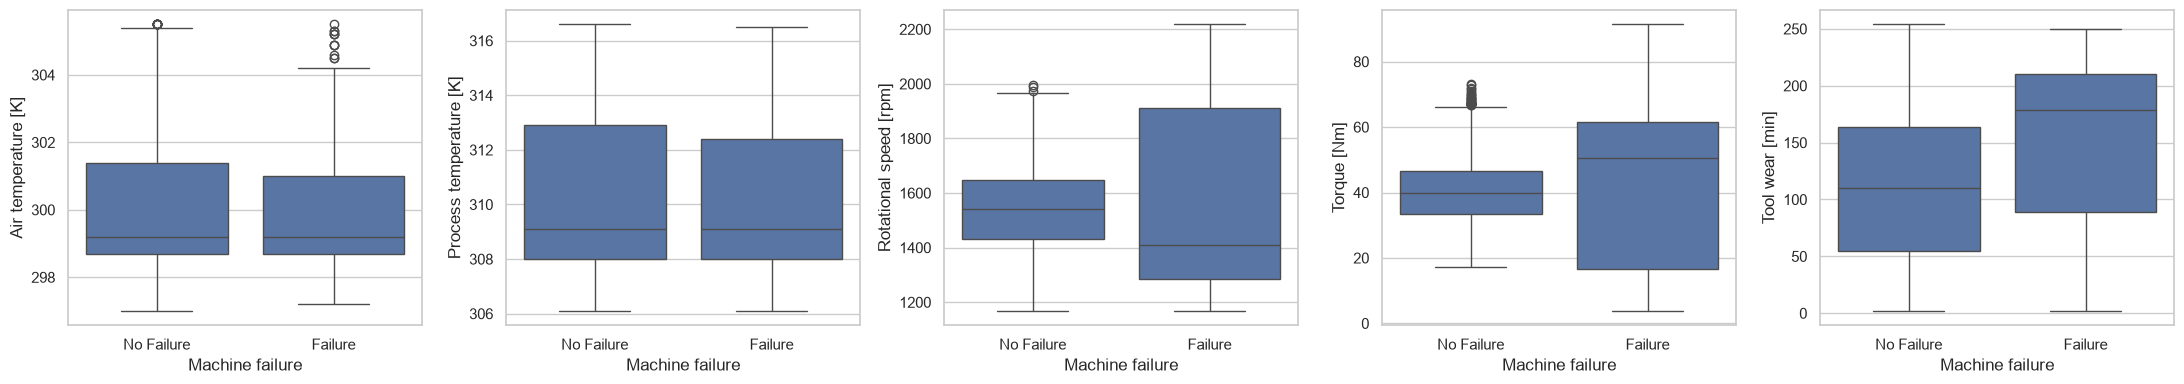

In [4]:
sensors = [config.COL_AIR_TEMP, config.COL_PROCESS_TEMP, config.COL_RPM, config.COL_TORQUE, config.COL_TOOL_WEAR]
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, sensors):
    sns.boxplot(data=df, x=config.TARGET, y=col, ax=ax)
    ax.set_xticklabels(['No Failure', 'Failure'])
plt.tight_layout()

## 4. Physics-based features
Power = torque x angular speed. Failures cluster at **very low and very high power**, which a simple linear model cannot separate, so tree-based models win.

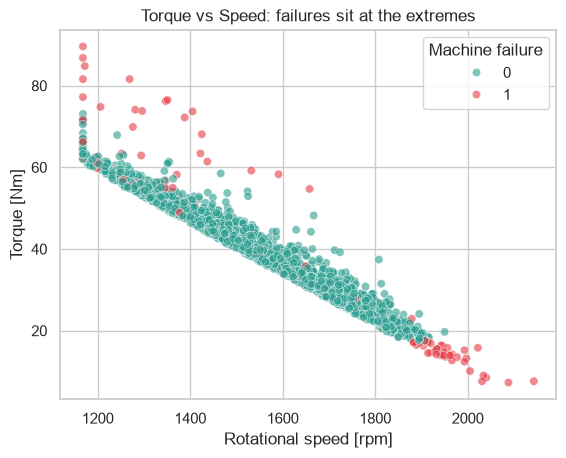

In [5]:
from src.feature_engineering import add_features
feat = add_features(df.drop(columns=config.DROP_COLUMNS))
sns.scatterplot(data=feat.sample(3000, random_state=0), x='Rotational speed [rpm]', y='Torque [Nm]',
                hue=config.TARGET, palette={0: '#2a9d8f', 1: '#e63946'}, alpha=0.6)
plt.title('Torque vs Speed: failures sit at the extremes');

## Key takeaways
- Failures are rare (imbalanced), so use **recall / F1**, not accuracy.
- Tool wear, torque and power are the strongest failure signals.
- Failure regions are non-linear, so try **Random Forest / Gradient Boosting**.

Next: run `python main.py train` to train the models.